## **Business Problem**

**Goal here is to see if we can harness the power of machine learning and boosting to help create not just a predictive model, but a general guidline for features people should look out for when picking mushrooms.**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('mushrooms.csv')
data.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

## **EDA**

In [4]:
X = pd.get_dummies(data.drop('class', axis = 1), drop_first=True)
y = data['class']

In [7]:
X.shape

(8124, 95)

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier()

gb_model.fit(X_train, y_train)

train_pred = gb_model.predict(X_train)
test_pred = gb_model.predict(X_test)

from sklearn.metrics import accuracy_score, confusion_matrix


print(accuracy_score(y_train, train_pred))
print(accuracy_score(y_test,test_pred))

print(confusion_matrix(y_test, test_pred))


from sklearn.model_selection import cross_val_score

score = cross_val_score(gb_model,X, y, cv = 5)

print(score)
print(score.mean())



0.9996922603477458
0.9993846153846154
[[851   0]
 [  1 773]]
[0.84246154 1.         1.         1.         0.75369458]
0.9192312239484653


## **Hyperparameter tuning**

In [12]:
from sklearn.model_selection import GridSearchCV

estimator = GradientBoostingClassifier()
param_grid = {'n_estimators':[1,5,10,20,40,100], 'learning_rate':[0.1,0.2,0.3,0.5,-0.8,1]}

grid = GridSearchCV(estimator, param_grid, cv = 5, scoring='accuracy')

grid.fit(X_train, y_train)
grid.best_params_

C:\Users\abhay\AppData\Roaming\Python\Python314\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
30 fits failed out of a total of 180.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\abhay\AppData\Roaming\Python\Python314\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\abhay\AppData\Roaming\Python\Python314\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\abhay\AppData\Roaming\Python

{'learning_rate': 0.5, 'n_estimators': 100}

## **Final Model**

In [ ]:
final_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.5)

final_model.fit(X_train, y_train)

train_pred = final_model.predict(X_train)
test_pred = final_model.predict(X_test)

print('Train Accuracy Score :', accuracy_score(train_pred, y_train))
print('Test Accuracy Score :', accuracy_score(test_pred, y_test))


Train Accuracy Score : 1.0
Test Accuracy Score : 1.0
CV Score : [0.84246154 1.         1.         1.         0.75184729]


**Feature Importance**

In [15]:
final_model.feature_importances_

array([1.40010839e-04, 0.00000000e+00, 0.00000000e+00, 5.24199854e-12,
       0.00000000e+00, 1.33254324e-03, 5.23415087e-10, 6.41983756e-06,
       2.86768840e-07, 0.00000000e+00, 0.00000000e+00, 3.41393133e-13,
       7.77314807e-17, 0.00000000e+00, 0.00000000e+00, 6.12791860e-09,
       3.92928523e-03, 4.94849014e-02, 1.66756714e-04, 2.00511009e-02,
       1.85945247e-02, 1.32175241e-05, 6.29439695e-01, 1.13543604e-03,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 2.36018115e-03,
       2.41959056e-03, 0.00000000e+00, 1.88122061e-17, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 2.19027200e-16,
       2.63295403e-03, 2.69939251e-04, 1.35990432e-01, 9.82005725e-03,
       1.64833368e-03, 1.02135265e-03, 6.46099093e-09, 2.40308828e-05,
       9.13053822e-07, 1.33918069e-12, 6.95941050e-02, 1.26251849e-06,
       0.00000000e+00, 0.00000000e+00, 6.63292187e-04, 0.00000000e+00,
      

In [19]:

imp_feats = pd.DataFrame(index=X.columns, data = grid.best_estimator_.feature_importances_, columns=['Importance'])
print(imp_feats)
imp_feats = imp_feats[imp_feats['Importance']>0.01]
print(imp_feats)

               Importance
cap-shape_c  1.400108e-04
cap-shape_f  0.000000e+00
cap-shape_k  1.077016e-17
cap-shape_s  5.241999e-12
cap-shape_x  0.000000e+00
...                   ...
habitat_l    8.961725e-04
habitat_m    0.000000e+00
habitat_p    6.025138e-09
habitat_u    5.920039e-08
habitat_w    3.001853e-10

[95 rows x 1 columns]
                            Importance
bruises_t                     0.049493
odor_l                        0.018595
odor_n                        0.629333
stalk-root_c                  0.135972
stalk-root_r                  0.057703
stalk-surface-above-ring_k    0.012333
stalk-surface-below-ring_y    0.013540
spore-print-color_h           0.016636
spore-print-color_r           0.028989


([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'bruises_t'),
  Text(1, 0, 'odor_l'),
  Text(2, 0, 'odor_n'),
  Text(3, 0, 'stalk-root_c'),
  Text(4, 0, 'stalk-root_r'),
  Text(5, 0, 'stalk-surface-above-ring_k'),
  Text(6, 0, 'stalk-surface-below-ring_y'),
  Text(7, 0, 'spore-print-color_h'),
  Text(8, 0, 'spore-print-color_r')])

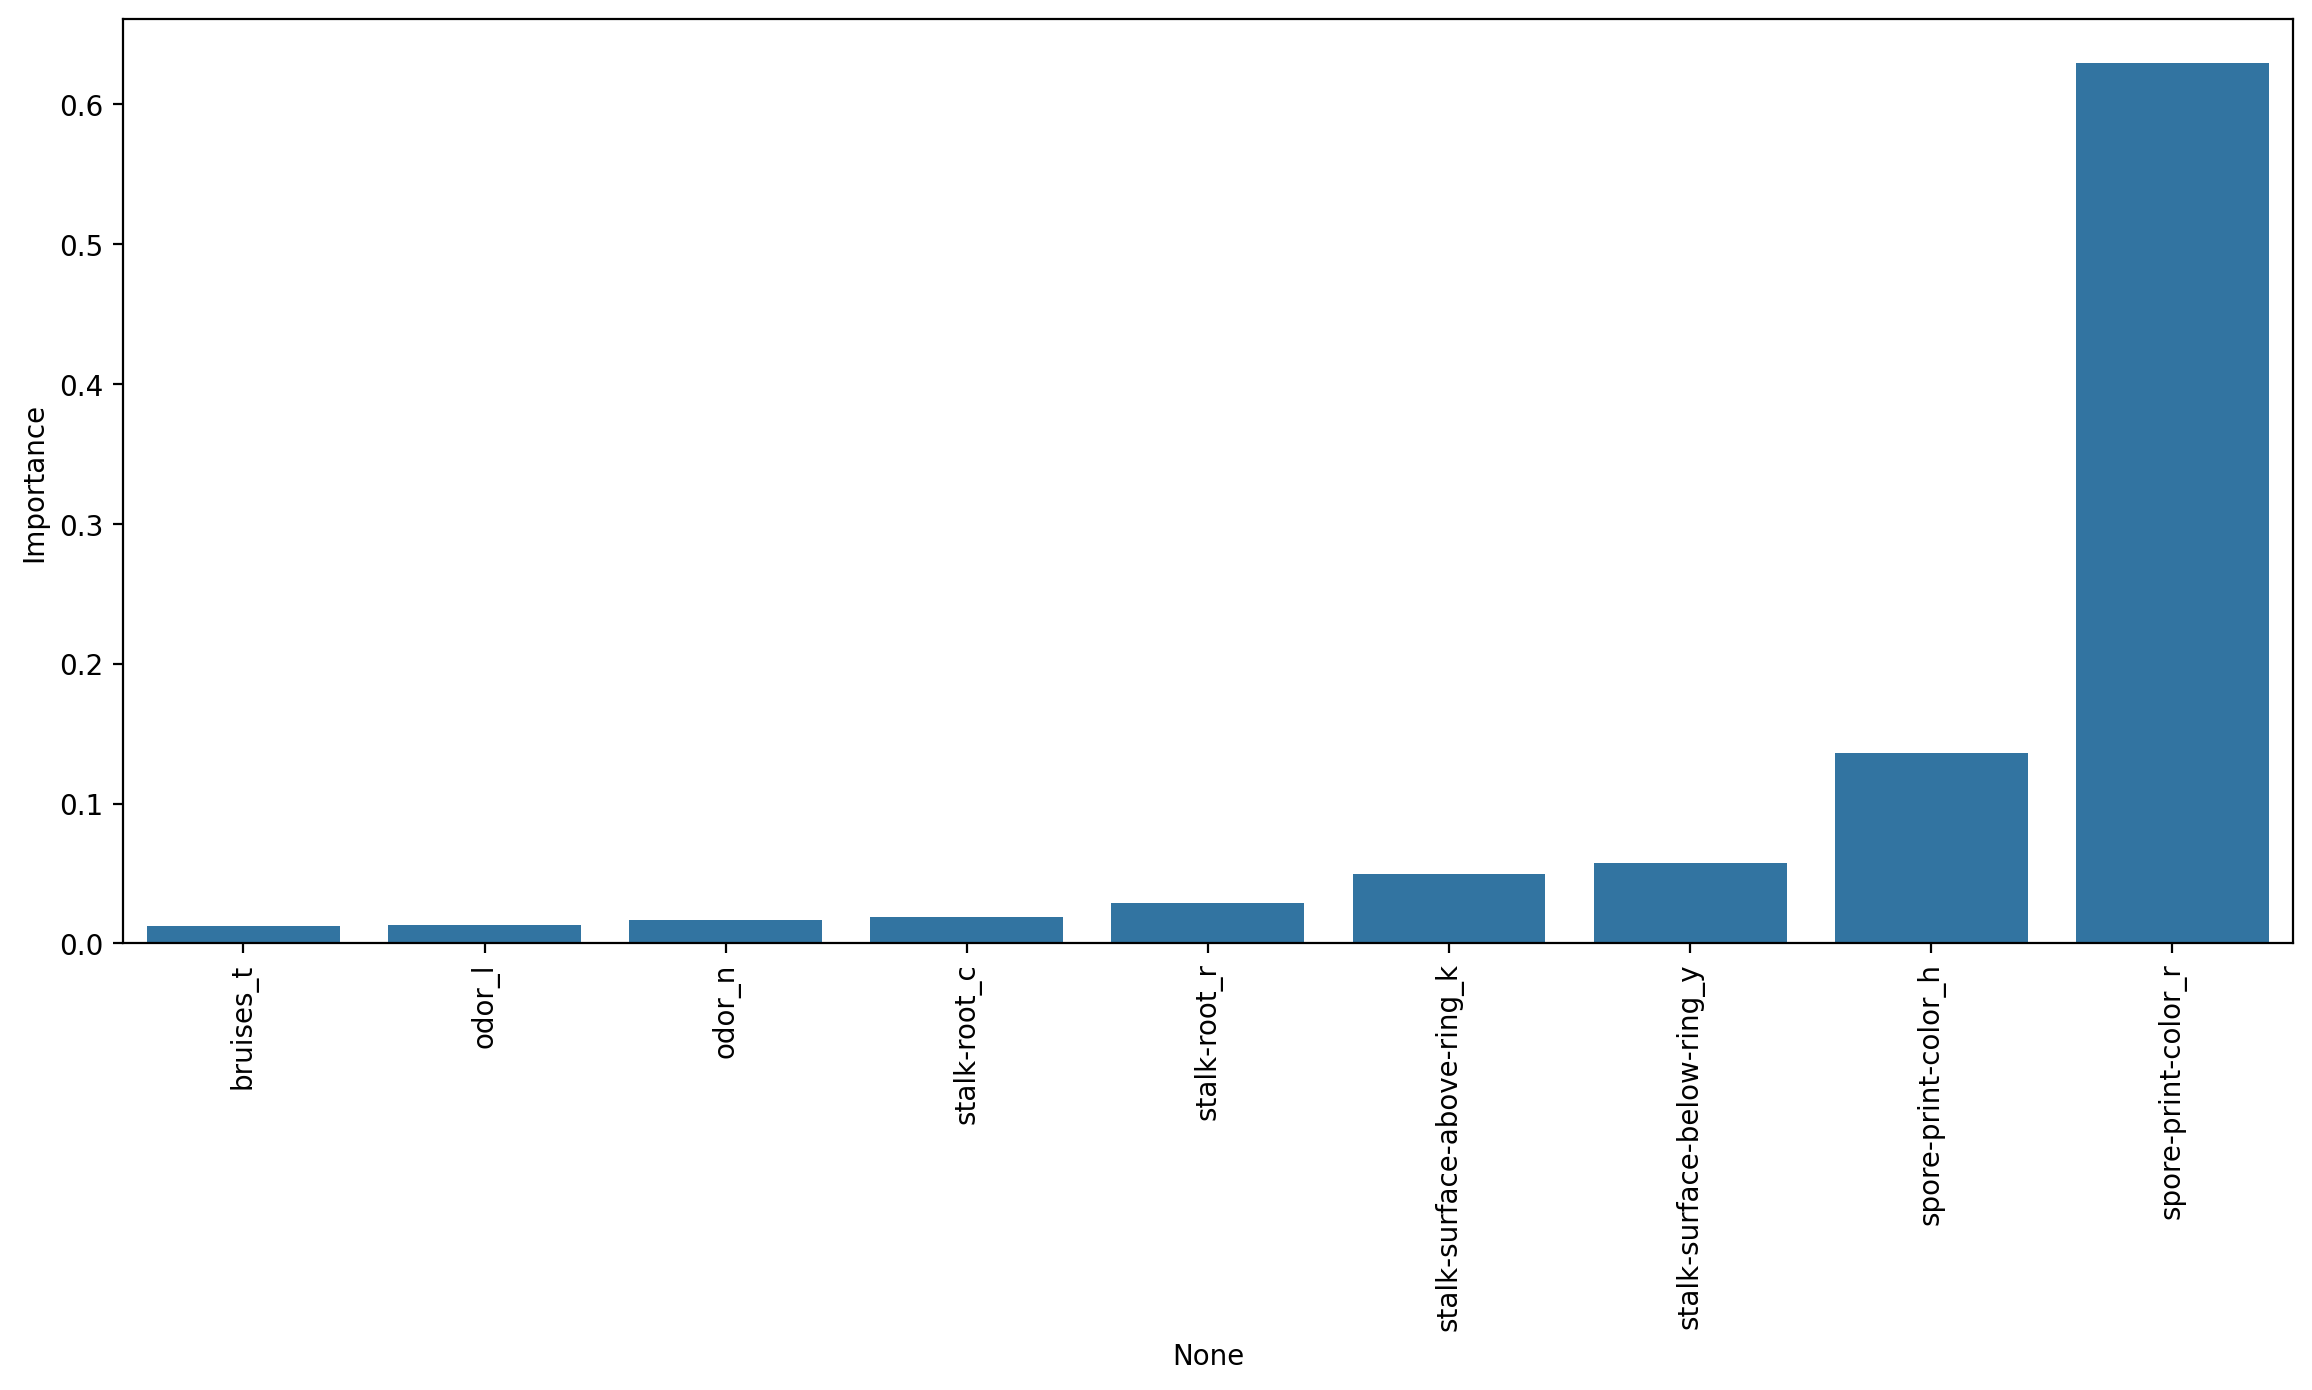

In [21]:
plt.figure(figsize=(14,6),dpi = 200)

sns.barplot(data = imp_feats.sort_values('Importance'), x = imp_feats.index, y = 'Importance')
plt.xticks(rotation = 90)

In [22]:
from sklearn.metrics import classification_report
print(classification_report(y_test, test_pred))

              precision    recall  f1-score   support

           e       1.00      1.00      1.00       851
           p       1.00      1.00      1.00       774

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625

